# Imports and loading dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, RocCurveDisplay

from xgboost import XGBClassifier
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)


train_df = pd.read_csv('/Users/gabrielaslomiany/PyCharmMiscProject/Small-ML/Airline Satisfaction/data/train.csv')
test_df = pd.read_csv('/Users/gabrielaslomiany/PyCharmMiscProject/Small-ML/Airline Satisfaction/data/test.csv')

print('train shape:', train_df.shape)
print('test shape:', test_df.shape)
train_df.head()

train shape: (699635, 23)
test shape: (299844, 22)


,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,1,3,4,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
1,1,56,651,5,5,5,5,5,4,4,5,5,5,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,True
2,2,31,1371,3,4,2,5,3,3,3,3,4,3,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
3,3,10,1616,3,5,3,3,3,3,3,3,4,5,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,False
4,4,23,481,3,4,3,4,5,3,5,5,5,4,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,False


# Checking training set

In [2]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 699635 entries, 0 to 699634
Data columns (total 23 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   id                                 699635 non-null  int64  
 1   Age                                699635 non-null  int64  
 2   Flight Distance                    699635 non-null  int64  
 3   Inflight wifi service              699635 non-null  int64  
 4   Departure/Arrival time convenient  699635 non-null  int64  
 5   Ease of Online booking             699635 non-null  int64  
 6   Gate location                      699635 non-null  int64  
 7   Food and drink                     699635 non-null  int64  
 8   Online boarding                    699635 non-null  int64  
 9   Seat comfort                       699635 non-null  int64  
 10  Inflight entertainment             699635 non-null  int64  
 11  On-board service                   699635 non-null

In [3]:
train_df.describe()

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes
count,699635.00000,699635.000000,699635.000000,699635.000000,699635.00000,699635.00000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699343.000000
mean,349817.00000,39.001928,1353.778702,2.778722,3.15621,2.81324,3.013734,3.265644,3.364156,3.568950,3.453910,3.517404,3.472847,3.805443,3.420291,3.380401,1.176209,1.134280
std,201967.37213,13.800943,954.422566,1.280419,1.47539,1.32955,1.254014,1.300202,1.288538,1.275333,1.308157,1.238474,1.271755,1.079175,1.210604,1.277870,5.982187,5.749304
min,0.00000,7.000000,67.000000,0.000000,0.00000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,174908.50000,27.000000,631.000000,2.000000,2.00000,2.00000,2.000000,2.000000,2.000000,3.000000,2.000000,3.000000,2.000000,3.000000,3.000000,2.000000,0.000000,0.000000
50%,349817.00000,40.000000,954.000000,3.000000,3.00000,3.00000,3.000000,3.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,0.000000,0.000000
75%,524725.50000,50.000000,1814.000000,4.000000,4.00000,4.00000,4.000000,4.000000,4.000000,5.000000,5.000000,4.000000,5.000000,5.000000,4.000000,4.000000,0.000000,0.000000
max,699634.00000,85.000000,4983.000000,5.000000,5.00000,5.00000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,489.000000,491.000000


### Checking for unique values

In [4]:
print(train_df['Gender'].unique())
print(train_df['Customer Type'].unique())
print(train_df['Type of Travel'].unique())
print(train_df['Class'].unique())

<StringArray>
['Female', 'Male']
Length: 2, dtype: str
<StringArray>
['Loyal Customer', 'disloyal Customer']
Length: 2, dtype: str
<StringArray>
['Personal Travel', 'Business travel']
Length: 2, dtype: str
<StringArray>
['Eco', 'Business', 'Eco Plus']
Length: 3, dtype: str


# EDA

### Missing data

In [5]:
print(train_df.columns)
print()
print(test_df.columns)

Index(['id', 'Age', 'Flight Distance', 'Inflight wifi service',
       'Departure/Arrival time convenient', 'Ease of Online booking',
       'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
       'Inflight entertainment', 'On-board service', 'Leg room service',
       'Baggage handling', 'Checkin service', 'Cleanliness',
       'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'Gender',
       'Customer Type', 'Type of Travel', 'Class', 'satisfaction'],
      dtype='str')

Index(['id', 'Age', 'Flight Distance', 'Inflight wifi service',
       'Departure/Arrival time convenient', 'Ease of Online booking',
       'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
       'Inflight entertainment', 'On-board service', 'Leg room service',
       'Baggage handling', 'Checkin service', 'Cleanliness',
       'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'Gender',
       'Customer Type', 'Type of Travel', 'Class'],
      dtype='str')


`'satisfaction'` is the target variable

In [6]:
missing_train = train_df.isna().sum()
missing_test = test_df.isna().sum()

missing_df = pd.DataFrame({'training_set': missing_train, 'test_set': missing_test})
missing_df

,training_set,test_set
Age,0,0.0
Arrival Delay in Minutes,292,130.0
Baggage handling,0,0.0
Checkin service,0,0.0
Class,0,0.0
Cleanliness,0,0.0
Customer Type,0,0.0
Departure Delay in Minutes,0,0.0
Departure/Arrival time convenient,0,0.0
Ease of Online booking,0,0.0


In [7]:
train_df['Arrival Delay in Minutes'].info()

<class 'pandas.Series'>
RangeIndex: 699635 entries, 0 to 699634
Series name: Arrival Delay in Minutes
Non-Null Count   Dtype  
--------------   -----  
699343 non-null  float64
dtypes: float64(1)
memory usage: 5.3 MB


In [8]:
col = 'Arrival Delay in Minutes'

n_missing = train_df[col].isna().sum()
n_total = len(train_df)
pct_missing = n_missing / n_total * 100

print(f"Missing: {n_missing} / {n_total} ({pct_missing:.2f}%)")

Missing: 292 / 699635 (0.04%)


Seeing that it is less than 5%, I will just drop missing values.

In [9]:
train_df = train_df.dropna()

In [10]:
train_df.isna().sum()

id                                   0
Age                                  0
Flight Distance                      0
Inflight wifi service                0
Departure/Arrival time convenient    0
Ease of Online booking               0
Gate location                        0
Food and drink                       0
Online boarding                      0
Seat comfort                         0
Inflight entertainment               0
On-board service                     0
Leg room service                     0
Baggage handling                     0
Checkin service                      0
Cleanliness                          0
Departure Delay in Minutes           0
Arrival Delay in Minutes             0
Gender                               0
Customer Type                        0
Type of Travel                       0
Class                                0
satisfaction                         0
dtype: int64

## Handling categorical features

In [11]:
print(train_df.select_dtypes(include=["object", "string"]).dtypes)

Gender            str
Customer Type     str
Type of Travel    str
Class             str
dtype: object


In [12]:
print(train_df['Gender'].unique())
print('----------------------------------------')
print(train_df['Customer Type'].unique())
print('----------------------------------------')
print(train_df['Type of Travel'].unique())
print('----------------------------------------')
print(train_df['Class'].unique())

<StringArray>
['Female', 'Male']
Length: 2, dtype: str
----------------------------------------
<StringArray>
['Loyal Customer', 'disloyal Customer']
Length: 2, dtype: str
----------------------------------------
<StringArray>
['Personal Travel', 'Business travel']
Length: 2, dtype: str
----------------------------------------
<StringArray>
['Eco', 'Business', 'Eco Plus']
Length: 3, dtype: str


`'Gender', 'Customer Type', 'Type of Travel'` --> binary values<br>
`'Class'` ---> ordinal values

In [13]:
ordinal_features = ['Class']
binary_features = ['Gender', 'Customer Type', 'Type of Travel']

ordinal_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(categories=[['Eco', 'Eco Plus', 'Business']])),
])

# binary_features: two categories, imputes missing with the most frequent category then encodes No/Yes as 0/1
binary_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(drop='if_binary')),
])

# combines the three encoders above, each applied to its own column(s)
categorical_pipeline = ColumnTransformer(transformers=[
    ('ordinal', ordinal_pipeline, ordinal_features),
    ('binary', binary_pipeline, binary_features),
])

In [14]:
numeric_features = [
    'Age', 'Flight Distance', 'Inflight wifi service',
    'Departure/Arrival time convenient', 'Ease of Online booking',
    'Gate location', 'Food and drink', 'Online boarding',
    'Seat comfort', 'Inflight entertainment', 'On-board service',
    'Leg room service', 'Baggage handling', 'Checkin service',
    'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes',
]

numeric_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])

In [15]:
preprocessor = ColumnTransformer(transformers=[
    ('numeric', numeric_pipeline, numeric_features),
    ('categorical', categorical_pipeline, ordinal_features + binary_features),
])

In [16]:
feature_columns = numeric_features + ordinal_features + binary_features

X = train_df[feature_columns]
y = train_df['satisfaction']
X_test = test_df[feature_columns]

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

In [17]:
print(X_train.shape)
print(X_val.shape)
print(y_train.shape)
print(y_val.shape)

(559474, 21)
(139869, 21)
(559474,)
(139869,)


In [18]:
results = {}
fitted_pipelines = {}

def evaluate(name, pipeline):
    pipeline.fit(X_train, y_train)
    val_pred = pipeline.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(y_val, val_pred)
    results[name] = auc
    fitted_pipelines[name] = pipeline
    print(f'{name:12s} validation ROC-AUC: {auc:.4f}')
    return pipeline

# Modeling

In [19]:
logreg_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(max_iter=1000, random_state=42)),
])

rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42)),
])

xgb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', XGBClassifier(
        n_estimators=200,
        eval_metric='auc',
        n_jobs=-1,
        random_state=42,
    )),
])

evaluate('LogReg', logreg_pipeline)
evaluate('RandomForest', rf_pipeline)
evaluate('XGBoost', xgb_pipeline)

LogReg       validation ROC-AUC: 0.9206
RandomForest validation ROC-AUC: 0.9540
XGBoost      validation ROC-AUC: 0.9571


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](21,)","['Age','Flight Distance','Inflight wifi service',...,'Gender', 'Customer Type','Type of Travel']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,21
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specify

## Comparing results

In [20]:
results_df = (
    pd.Series(results, name='roc_auc')
    .sort_values(ascending=False)
    .rename_axis('model')
    .reset_index()
)
results_df

,model,roc_auc
0,XGBoost,0.957089
1,RandomForest,0.954019
2,LogReg,0.920556


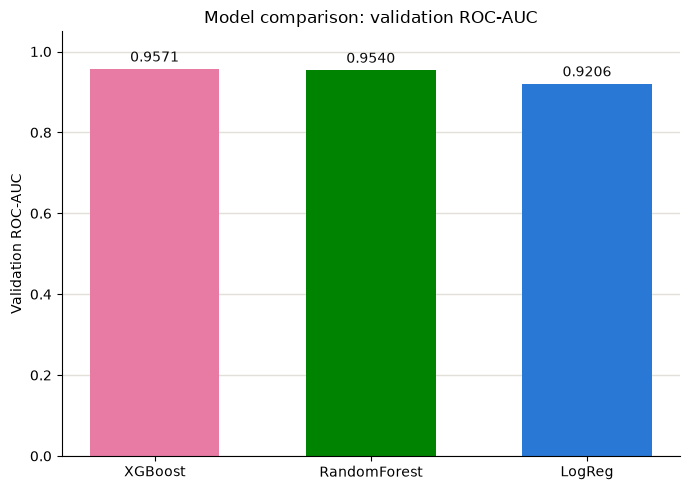

In [21]:
model_colors = {
    'LogReg': '#2a78d6',
    'RandomForest': '#008300',
    'XGBoost': '#e87ba4',
}
bar_colors = results_df['model'].map(model_colors)

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(results_df['model'], results_df['roc_auc'], color=bar_colors, width=0.6)

ax.set_ylim(0, 1.05)
ax.set_ylabel('Validation ROC-AUC')
ax.set_title('Model comparison: validation ROC-AUC')
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', color='#e1e0d9', linewidth=1, zorder=0)
ax.set_axisbelow(True)

for bar, score in zip(bars, results_df['roc_auc']):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01,
             f'{score:.4f}', ha='center', va='bottom', fontsize=10, color='#0b0b0b')

plt.tight_layout()
plt.show()